<a href="https://colab.research.google.com/github/mrbedoya/ml-2026/blob/main/03_RegresionLineal(2da_Parte).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión Lineal

## 1. Librerias y configuraciones previas


In [1]:
# Tratamiento de datos
# ==============================================================================
import pandas as pd
import numpy as np


# Preprocesado y modelado
# ==============================================================================

#Separar los datos entrenamiento y prueba
from sklearn.model_selection import train_test_split

#Escalar Variables
from sklearn.preprocessing import MinMaxScaler

#Creación de modelo
from statsmodels import api as sm
from statsmodels.tools.sm_exceptions import SingularMatrixWarning
#from sklearn.linear_model import LinearRegression  # alternativa con scikit-learn (ver "Creación del modelo"); aquí se usa statsmodels

#Evaluación del modelo
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                            median_absolute_error)

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Interactuar con el sistema operativo y solicitudes HTTP
# ==============================================================================
import os
import sys
import requests
from urllib.parse import urljoin

# Configuración warnings
# ==============================================================================
import warnings
# Se ocultan solo los avisos informativos de versiones; los demás avisos siguen visibles
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
# Aviso de matplotlib que genera internamente sm.qqplot al personalizar el color de los puntos (no afecta el resultado)
warnings.filterwarnings('ignore', message='.*redundantly defined by the')

In [2]:
# Parametros globales
# ==============================================================================

# URL base de GitHub para el repositorio
GITHUB_BASE_URL = 'https://raw.githubusercontent.com/mrbedoya/ml-2026/main/'

# Nombres de los archivos requeridos
DATASET_FILE_NAME = '01_carDetailsV4_Prep.csv'
UTILS_FILE_NAME = 'funciones.py'

# Nombres de los directorios para utilidades y datasets
DATASETS_PATH = 'datasets/'
UTILS_PATH = 'utils/'

# URL completa del dataset y utils en GitHub (urljoin evita errores con las barras)
github_dataset_url = urljoin(GITHUB_BASE_URL, DATASETS_PATH + DATASET_FILE_NAME)
github_utils_url = urljoin(GITHUB_BASE_URL, UTILS_PATH + UTILS_FILE_NAME)

# Rutas locales completas de datasets y utils
local_dataset_path = os.path.join(DATASETS_PATH, DATASET_FILE_NAME)
local_utils_path = os.path.join(UTILS_PATH, UTILS_FILE_NAME)

### (Opcional) Cargar datos desde Google Drive

La celda siguiente muestra una **alternativa** para trabajar con archivos guardados en Google Drive, en vez de descargarlos desde GitHub. Se deja comentada porque en este notebook usamos la descarga directa desde el repositorio (más fácil de reproducir para cualquier estudiante), pero queda como referencia por si prefieres montar tu propio Drive.

In [3]:
## Cargar datos desde Google Drive
## ==============================================================================

#from google.colab import drive

## Montar Google Drive
#drive.mount('/gdrive')

## Establece el directorio de trabajo dentro de directorio especificado en Google Drive
#os.chdir("/gdrive/MyDrive/01_Academia/02_Cursos/20260401_ApredinzajeAutomáticoI_UdeA/")

## Listar archivos de directorio
##!ls

In [4]:
# Funcion local para la carga de archivos
# ==============================================================================

def download_file(url, path, description, force=False, timeout=30):
    '''
    Descarga un archivo desde una URL y lo guarda localmente en un path.
    Si el archivo ya existe no se vuelve a descargar (usar force=True para obligarlo).

    Args:
        url (str): URL del archivo
        path (str): Ruta local de destino
        description (str): Descripción del archivo
        force (bool): Si es True, descarga aunque el archivo ya exista
        timeout (int): Segundos máximos de espera de la descarga
    Returns:
        None
    '''
    if os.path.exists(path) and not force:
        print(f"{description} ya existe en: {path} (no se vuelve a descargar)")
        return

    print(f"Descargando {description} desde: {url}")

    # Realiza una solicitud HTTP GET a la URL proporcionada
    response = requests.get(url, timeout=timeout)

    # Lanza una excepción si la descarga falla (código de estado HTTP no 200)
    response.raise_for_status()

    # Abre el archivo local en modo de escritura binaria ('wb')
    with open(path, 'wb') as f:
        # Escribe el contenido binario de la respuesta HTTP en el archivo local
        f.write(response.content)

    # Imprime un mensaje confirmando que la descarga fue exitosa y la ruta de guardado
    print(f"{description} descargado exitosamente a: {path}")

In [5]:
# Configuración entorno Colab
# ==============================================================================

# Creación de directorios locales
os.makedirs(DATASETS_PATH, exist_ok=True)
os.makedirs(UTILS_PATH, exist_ok=True)

# Descarga de archivos
download_file(github_dataset_url, local_dataset_path, "dataset")
download_file(github_utils_url, local_utils_path, "funciones")

dataset ya existe en: datasets/01_carDetailsV4_Prep.csv (no se vuelve a descargar)
funciones ya existe en: utils/funciones.py (no se vuelve a descargar)


## 2. Funciones

En esta sección importamos las funciones reutilizables de `funciones.py` (descargado arriba). Aquí usaremos `multiple_plot`, `tidy_corr_matrix`, `check_vif`.

In [6]:
# Funciones externas
# ==============================================================================

# Añade la ruta definida en 'UTILS_PATH' al 'sys.path' para que Python pueda encontrar módulos
sys.path.append(UTILS_PATH)

# Importa funciones externas
from funciones import multiple_plot, tidy_corr_matrix, check_vif

In [7]:
# Función para construir un modelo de regresión lineal por medio de statsmodels.api

def build_model(X,y):
    '''
    Crea y entrena un modelo de regresión lineal (OLS) con statsmodels e imprime su resumen.

    Si las variables tienen colinealidad perfecta (alguna es combinación exacta de otras) los
    coeficientes no son únicos: se informa con un mensaje y no con el SingularMatrixWarning de statsmodels.

    Args:
        X (DataFrame): variables de entrada (a las que se les adiciona la constante)
        y (array): variable de salida
    Returns:
        DataFrame: 'X' con la constante adicionada (se reutiliza en la siguiente iteración)
    '''

    #A los datos de entrada 'X' se le adiciona una constante
    X = sm.add_constant(X)

    #Se verifica si hay colinealidad perfecta: el rango de la matriz es menor que el número de columnas
    redundantes = X.shape[1] - np.linalg.matrix_rank(X.to_numpy(dtype=float))
    if redundantes > 0:
        print(f"Aviso: hay colinealidad perfecta ({redundantes} variable(s) redundante(s)); "
              "los coeficientes no son únicos. Revisa el VIF (valores muy altos o inf) y elimina variables.")

    #Se crea y se entrena el modelo de regresión lineal (statsmodels.api) con
    #los datos de entrada 'X' y los datos de salida 'y'
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', SingularMatrixWarning)   # ya se informó arriba, una sola vez
        lm = sm.OLS(y,X).fit()

    #imprime el resumen del modelo creado
    print(lm.summary()) # model summary

    return X

## 3. Carga del dataset

In [8]:
#Se crea un dataframe d con los datos obtenidos de archivo de entrada
d = pd.read_csv(local_dataset_path)

In [9]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1516 non-null   float64
 1   Year                1516 non-null   int64  
 2   Kilometer           1516 non-null   int64  
 3   Engine              1516 non-null   float64
 4   Length              1516 non-null   float64
 5   Width               1516 non-null   float64
 6   Height              1516 non-null   float64
 7   Seating Capacity    1516 non-null   float64
 8   Fuel Tank Capacity  1516 non-null   float64
 9   Fuel Type           1516 non-null   object 
 10  Transmission        1516 non-null   object 
 11  Owner               1516 non-null   object 
 12  Seller Type         1516 non-null   object 
 13  Drivetrain          1516 non-null   object 
 14  PriceRange          1516 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 177.8+

## 4. Visualización de datos

### Variables de entrada

In [10]:
#Lista de variables categóricas
catCols = d.select_dtypes(include = ["object", 'category']).columns.tolist()

d[catCols].head(2)

,Fuel Type,Transmission,Owner,Seller Type,Drivetrain
0,Petrol,Manual,First,Individual,FWD
1,Petrol,Manual,First,Individual,FWD


In [11]:
#Lista de variables numéricas

numCols=d.select_dtypes(include = ['float64','float64','int32','int64']).columns.tolist()
d[numCols].head(2)

,Price,Year,Kilometer,Engine,Length,Width,Height,Seating Capacity,Fuel Tank Capacity,PriceRange
0,9300.0,2020,39000,1197.0,3995.0,1775.0,1505.0,5.0,37.0,0
1,7500.0,2019,31000,1197.0,3985.0,1734.0,1505.0,5.0,45.0,0


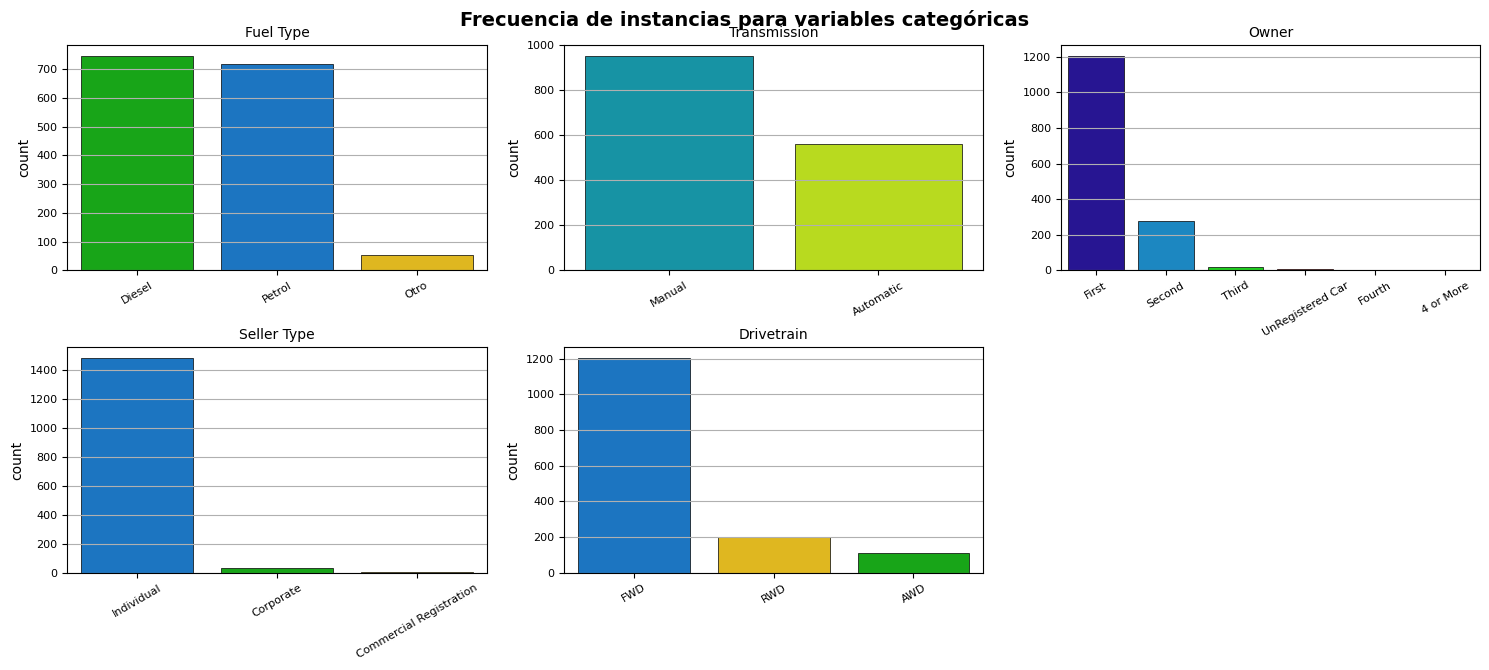

In [12]:
##Visualización de frecuencia de instancias para variables categóricas
multiple_plot(3, d , catCols, None, 'countplot', 'Frecuencia de instancias para variables categóricas',30)

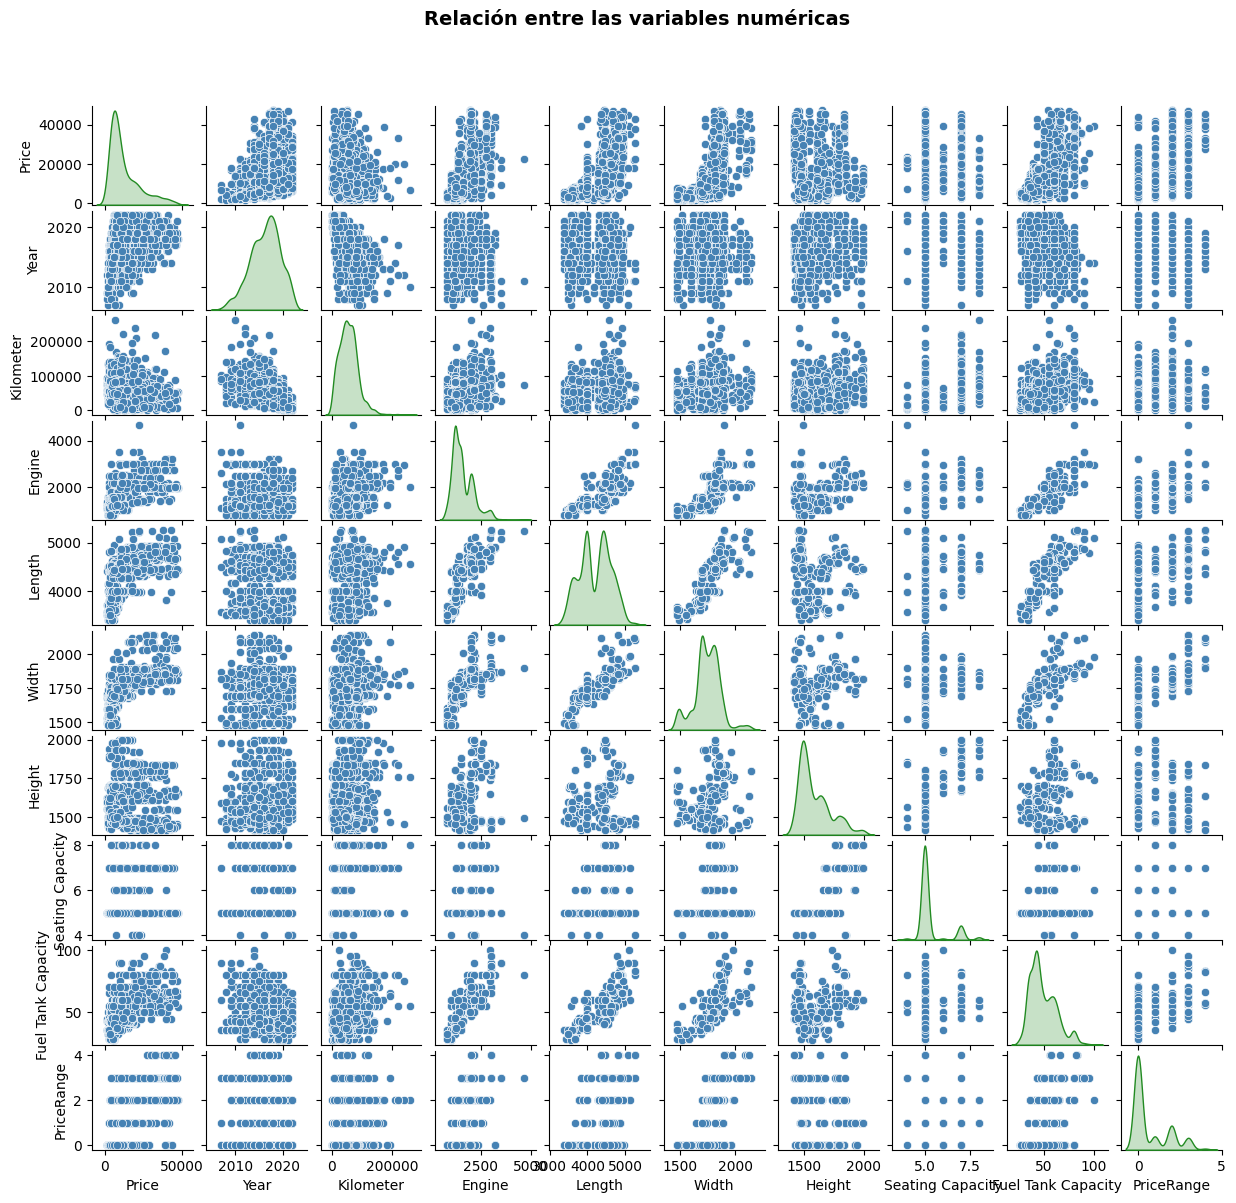

In [13]:
#Visualización de variables numéricas con respecto al precio
multiple_plot(1, d , numCols, None, 'scatterplot', 'Relación entre las variables numéricas',30)

### Variable de salida

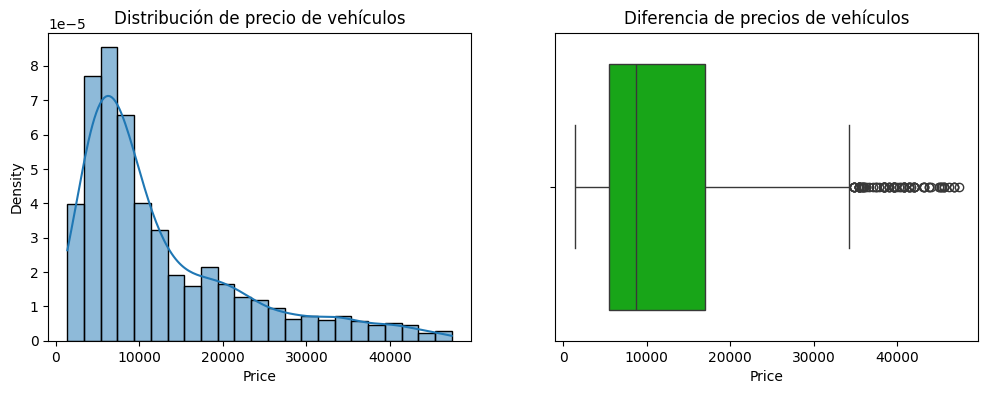

In [14]:
#Histograma y caja de bigotes del precio de los vehículos

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución de precio de vehículos')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

In [15]:
pd.set_option('display.float_format', lambda x: '%.0f' % x)

print(d.Price.describe(percentiles = [0.25,0.50,0.75,0.85,0.90,0.95,0.975,1]))

count    1516
mean    12591
std      9993
min      1380
25%      5520
50%      8700
75%     17043
85%     22761
90%     28530
95%     35400
97.5%   39938
100%    47400
max     47400
Name: Price, dtype: float64


In [16]:
# Eliminar el valor 'Price' de la lista
numCols.remove('Price')

## 5. Preparación de datos

### Transformaciones para la variable de salida

In [17]:
#Transformación y = y^(1/3) Raíz cúbica

d['Price'] = np.cbrt(d['Price'])

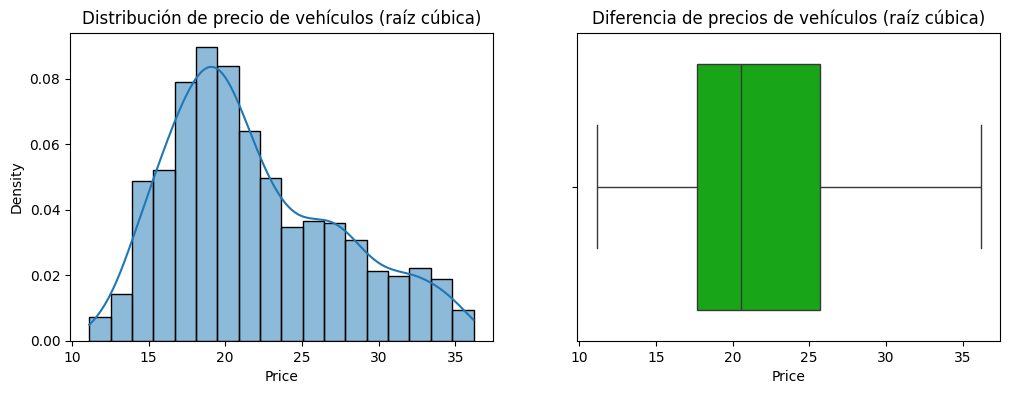

In [18]:
#Histograma y caja de bigotes del precio de los vehículos transformado

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.title('Distribución de precio de vehículos (raíz cúbica)')
sns.histplot(d.Price, kde=True, stat='density')

plt.subplot(1,2,2)
plt.title('Diferencia de precios de vehículos (raíz cúbica)')
sns.boxplot(x=d.Price, palette='nipy_spectral')

plt.show()

### Transformaciones a las variables de entrada

In [19]:
varTrans = ['Price', 'Year','Engine','Length','Width','Fuel Tank Capacity']

#multiple_plot(1, d , varTrans, None, 'scatterplot', 'Relación entre las variables numéricas',30)

In [20]:
# Transformaciones X = X^2 a las variables de entrada

varTrans = ['Year','Length','Width','Fuel Tank Capacity']

for elemento in varTrans:
    d[elemento]   = d[elemento] ** 2

### Correlaciones

In [21]:
#Generación de la matriz de correlación (incluye la variable de salida 'Price')
matrizCorr = d[['Price']+numCols].corr()

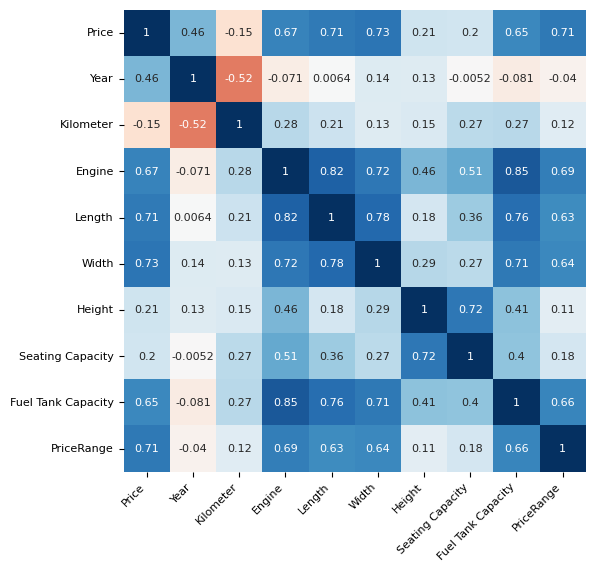

In [22]:
# Mapa de calor (Heatmap) de la matriz de correlaciones

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 6))

sns.heatmap(
    matrizCorr,
    annot     = True,
    cbar      = False,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = 'RdBu', #sns.diverging_palette(20, 220, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)


ax.tick_params(labelsize = 8)


In [23]:
#Matriz de correlación ordenada

pd.set_option('display.float_format', lambda x: '%.4f' % x)

#Creación de la matriz
df_corr= tidy_corr_matrix(matrizCorr)

#Selección de las variables correlacionadas con el precio
df_filtrado = df_corr.loc[df_corr['variable_2'] == 'Price']

#Se identifican las correlaciones más fuertes
df_filtrado[df_filtrado['abs_r']>=0.5]

,variable_1,variable_2,r,abs_r
50,Width,Price,0.7335,0.7335
90,PriceRange,Price,0.7110,0.7110
40,Length,Price,0.7092,0.7092
30,Engine,Price,0.6707,0.6707
80,Fuel Tank Capacity,Price,0.6458,0.6458


In [24]:
#Cantidad de variables más relevantes extraidas a partir de la matriz de correlación ordenada
VarRelevantes = df_filtrado[df_filtrado['abs_r']>=0.5].shape[0]

#Creacion de la lista de variables más relevantes (inicialmente numéricas)
vDep =df_filtrado['variable_1'][:VarRelevantes].tolist()
print(vDep)

['Width', 'PriceRange', 'Length', 'Engine', 'Fuel Tank Capacity']


In [25]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Price               1516 non-null   float64
 1   Year                1516 non-null   int64  
 2   Kilometer           1516 non-null   int64  
 3   Engine              1516 non-null   float64
 4   Length              1516 non-null   float64
 5   Width               1516 non-null   float64
 6   Height              1516 non-null   float64
 7   Seating Capacity    1516 non-null   float64
 8   Fuel Tank Capacity  1516 non-null   float64
 9   Fuel Type           1516 non-null   object 
 10  Transmission        1516 non-null   object 
 11  Owner               1516 non-null   object 
 12  Seller Type         1516 non-null   object 
 13  Drivetrain          1516 non-null   object 
 14  PriceRange          1516 non-null   int64  
dtypes: float64(7), int64(3), object(5)
memory usage: 177.8+

In [26]:
d.columns

Index(['Price', 'Year', 'Kilometer', 'Engine', 'Length', 'Width', 'Height',
       'Seating Capacity', 'Fuel Tank Capacity', 'Fuel Type', 'Transmission',
       'Owner', 'Seller Type', 'Drivetrain', 'PriceRange'],
      dtype='object')

In [27]:
# Se adiciona a la lista de variables numericas más relevantes todas las variables categóricas
vDep += catCols

vDep

['Width',
 'PriceRange',
 'Length',
 'Engine',
 'Fuel Tank Capacity',
 'Fuel Type',
 'Transmission',
 'Owner',
 'Seller Type',
 'Drivetrain']

In [28]:
d = d[vDep  +['Price']]

In [29]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Width               1516 non-null   float64
 1   PriceRange          1516 non-null   int64  
 2   Length              1516 non-null   float64
 3   Engine              1516 non-null   float64
 4   Fuel Tank Capacity  1516 non-null   float64
 5   Fuel Type           1516 non-null   object 
 6   Transmission        1516 non-null   object 
 7   Owner               1516 non-null   object 
 8   Seller Type         1516 non-null   object 
 9   Drivetrain          1516 non-null   object 
 10  Price               1516 non-null   float64
dtypes: float64(5), int64(1), object(5)
memory usage: 130.4+ KB


### Creación de Variables Dummies

In [30]:
# Aplicación de la función de get_dummies

d =pd.get_dummies(d, dtype=int ,drop_first=1)

In [31]:
d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Width                   1516 non-null   float64
 1   PriceRange              1516 non-null   int64  
 2   Length                  1516 non-null   float64
 3   Engine                  1516 non-null   float64
 4   Fuel Tank Capacity      1516 non-null   float64
 5   Price                   1516 non-null   float64
 6   Fuel Type_Otro          1516 non-null   int64  
 7   Fuel Type_Petrol        1516 non-null   int64  
 8   Transmission_Manual     1516 non-null   int64  
 9   Owner_First             1516 non-null   int64  
 10  Owner_Fourth            1516 non-null   int64  
 11  Owner_Second            1516 non-null   int64  
 12  Owner_Third             1516 non-null   int64  
 13  Owner_UnRegistered Car  1516 non-null   int64  
 14  Seller Type_Corporate   1516 non-null   

## 6. Creación del modelo

### Dividir el conjunto de datos

In [32]:
#Se crea una lista con todas las variables de entrada

vDep = list(d.columns)
vDep.remove('Price')

#Se establece las variables de entrada 'X' y la variable de salida 'y'
X = d.drop(columns ='Price')
y = d['Price']

In [33]:
# División de los datos en train y test

#En este caso, el 80% de los datos se utilizarán para entrenar el modelo.

X_train, X_test, y_train, y_test = train_test_split(
                                        X,
                                        y.values.reshape(-1,1),
                                        train_size   = 0.8,
                                        random_state = 1234,
                                        shuffle      = True
                                    )

In [34]:
#Se establecen las variables numéricas a escalar

#Num_vars contiene la intersección de variables de las listas numCols y vDep (se conserva el orden de numCols)
num_vars = [col for col in numCols if col in vDep]

print(num_vars)

['Engine', 'Length', 'Width', 'Fuel Tank Capacity', 'PriceRange']


### Escalar Variables

In [35]:
#Escalar Variables númericas

pd.set_option('display.float_format', lambda x: '%.4f' % x)

# Se crea un objeto MinMaxScaler
scaler = MinMaxScaler()

# Se escalan los valores del dataset entrenamiento y prueba de las columnas numéricas
X_train[num_vars] = scaler.fit_transform(X_train[num_vars])
X_test[num_vars] = scaler.transform(X_test[num_vars])

X_train[num_vars].head()

,Engine,Length,Width,Fuel Tank Capacity,PriceRange
89,0.2229,0.2490,0.3108,0.1562,0.0000
166,0.1494,0.2053,0.2896,0.1248,0.0000
201,0.4991,0.4972,0.4480,0.2135,0.7500
1434,0.6713,0.5405,0.4675,0.3461,0.2500
959,0.2917,0.4715,0.2966,0.1350,0.0000


In [36]:
X_train.head(2)

,Width,PriceRange,Length,Engine,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_First,Owner_Fourth,Owner_Second,Owner_Third,Owner_UnRegistered Car,Seller Type_Corporate,Seller Type_Individual,Drivetrain_FWD,Drivetrain_RWD
89,0.3108,0.0000,0.2490,0.2229,0.1562,0,1,0,1,0,0,0,0,0,1,1,0
166,0.2896,0.0000,0.2053,0.1494,0.1248,0,1,1,1,0,0,0,0,0,1,1,0


### Creación del modelo y selección de variables

#### Colinealidad

In [37]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Seller Type_Individual,240.9000
1,Owner_First,220.8600
2,Owner_Second,48.5000
3,Length,22.7000
4,Engine,22.1900
5,Drivetrain_FWD,21.4900
6,Width,19.5800
7,Fuel Tank Capacity,11.8400
8,Seller Type_Corporate,6.3300
9,Owner_Third,4.6300


Si existe alguna *feature* > 10 (siendo estrictos con VIF > 5) se convierte en candidata a eliminar. Si No aporta valor predictivo (*p-value* mayor a 0.05), se recomienda eliminar.

In [38]:
#Se elimina la variable 'Seller Type_Individual'
X_train = X_train.drop(["Seller Type_Individual"], axis = 1)

In [39]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Owner_First,43.9600
1,Length,22.6800
2,Engine,22.0900
3,Drivetrain_FWD,21.3600
4,Width,19.5100
5,Fuel Tank Capacity,11.8400
6,Owner_Second,9.9400
7,Transmission_Manual,4.0400
8,PriceRange,3.6500
9,Fuel Type_Petrol,3.3600


In [40]:
#Se elimina la variable 'Owner_First'
X_train = X_train.drop(["Owner_First"], axis = 1)

In [41]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Length,21.7100
1,Engine,18.6200
2,Width,16.2200
3,Fuel Tank Capacity,11.7300
4,Drivetrain_FWD,10.1000
5,PriceRange,3.6300
6,Transmission_Manual,3.5000
7,Drivetrain_RWD,2.7200
8,Fuel Type_Petrol,2.6500
9,Owner_Second,1.2800


In [42]:
#Se elimina la variable 'Length'
X_train = X_train.drop(["Length"], axis = 1)

In [43]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Engine,14.5500
1,Width,13.8900
2,Fuel Tank Capacity,11.5200
3,Drivetrain_FWD,8.9700
4,PriceRange,3.6200
5,Transmission_Manual,3.3100
6,Drivetrain_RWD,2.6700
7,Fuel Type_Petrol,2.6500
8,Owner_Second,1.2700
9,Fuel Type_Otro,1.2200


In [44]:
#Se elimina la variable 'Engine'
X_train = X_train.drop(["Engine"], axis = 1)

In [45]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Width,12.5700
1,Drivetrain_FWD,8.9600
2,Fuel Tank Capacity,7.2000
3,PriceRange,3.5400
4,Transmission_Manual,3.2700
5,Fuel Type_Petrol,2.6300
6,Drivetrain_RWD,2.5800
7,Owner_Second,1.2700
8,Fuel Type_Otro,1.2100
9,Seller Type_Corporate,1.0400


In [46]:
#Se elimina la variable 'Width'
X_train = X_train.drop(["Width"], axis = 1)

In [47]:
#Se aplica la funcion de Factor de Inflación de la Varianza (VIF- Variance Inflation Factor) para identificar colinealidad
#entre las variables

check_vif(X_train)

,Features,VIF
0,Drivetrain_FWD,6.2100
1,Fuel Tank Capacity,4.0800
2,PriceRange,3.2800
3,Transmission_Manual,3.2700
4,Fuel Type_Petrol,2.5900
5,Drivetrain_RWD,2.3300
6,Owner_Second,1.2700
7,Fuel Type_Otro,1.1300
8,Seller Type_Corporate,1.0400
9,Owner_Fourth,1.0200


In [48]:
#Llamamos la funcion build_model definida al principio de este notebook que crea y entrena el modelo

modelo_X_train = build_model(X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     211.0
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          2.54e-285
Time:                        05:01:32   Log-Likelihood:                -3123.3
No. Observations:                1212   AIC:                             6273.
Df Residuals:                    1199   BIC:                             6339.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     23

Dado que el p-value de `Seller Type_Individual` es mayor a 0.05 no hay suficiente evidencia para sugerir que la variable
independiente tiene un efecto significativo sobre la variable dependiente

In [49]:
#Se elimina la variable 'Owner_UnRegistered Car'
modelo_X_train = modelo_X_train.drop(["Owner_UnRegistered Car"], axis = 1)

In [50]:
# Colinealidad
check_vif(modelo_X_train)

,Features,VIF
0,Drivetrain_FWD,3.6400
1,Drivetrain_RWD,2.7000
2,Fuel Tank Capacity,2.4300
3,PriceRange,2.3700
4,Fuel Type_Petrol,1.4900
5,Transmission_Manual,1.4600
6,Fuel Type_Otro,1.1200
7,Owner_Second,1.0500
8,Seller Type_Corporate,1.0200
9,Owner_Fourth,1.0100


In [51]:
#Llamamos la funcion build_model definida al principio de este notebook que crea y entrena el modelo

modelo_X_train = build_model(modelo_X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.679
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     230.3
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.96e-286
Time:                        05:01:33   Log-Likelihood:                -3123.5
No. Observations:                1212   AIC:                             6271.
Df Residuals:                    1200   BIC:                             6332.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    23.64

In [52]:
#Se elimina la variable 'Seller Type_Corporate'
modelo_X_train = modelo_X_train.drop(["Seller Type_Corporate"], axis = 1)

In [53]:
# Colinealidad
check_vif(modelo_X_train)

,Features,VIF
0,Drivetrain_FWD,3.6400
1,Drivetrain_RWD,2.7000
2,Fuel Tank Capacity,2.4300
3,PriceRange,2.3700
4,Fuel Type_Petrol,1.4900
5,Transmission_Manual,1.4500
6,Fuel Type_Otro,1.1200
7,Owner_Second,1.0500
8,Owner_Fourth,1.0100
9,Owner_Third,1.0100


In [54]:
modelo_X_train = build_model(modelo_X_train,y_train)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.678
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     253.4
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.52e-287
Time:                        05:01:33   Log-Likelihood:                -3123.8
No. Observations:                1212   AIC:                             6270.
Df Residuals:                    1201   BIC:                             6326.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  23.6471    

In [55]:
#Se crea nuevamente el modelo con las variables anteriormente


#Se crea y se entrena el modelo de regresion lineal q(statsmodels.api)
modelLRegresion  = sm.OLS(y_train,modelo_X_train).fit()

#No es necesario adicionar la constante porque los datos devueltos en la variable 'modelo_X_train' ya contiene la constante

In [56]:
# Si se creara el modelo en sklearn

#from sklearn.linear_model import LinearRegression

# Crear un modelo de regresión lineal
#modeloLR = LinearRegression()

#modeloLR.fit(modelo_X_train, y_train)

## 7. Evaluación del modelo

### Entrenamiento

In [57]:
# Diagnóstico errores (residuos) de las predicciones de entrenamiento

#Reducción de dimensionalidad del dataset: se convierte en una dimensión
y_train = y_train.flatten()

#Se realiza la predicción sobre los datos de entrenamiento
prediccion_train = modelLRegresion.predict(modelo_X_train)

#Se calculan los residuos: diferencia entre la prediccion y el valor real en los datos de entrenamiento
residuos_train   = prediccion_train - y_train

In [58]:
# Error de Entrenamiento del modelo


predicciones = modelLRegresion.predict(modelo_X_train)

mse = mean_squared_error (y_true  = y_train, y_pred  = predicciones)
rmse = np.sqrt(mse)
MAE = mean_absolute_error (y_true  = y_train, y_pred  = predicciones)
MedAE = median_absolute_error (y_true  = y_train, y_pred  = predicciones)
r2 = r2_score (y_true  = y_train, y_pred  = predicciones)

print(f"El error MSE   de train es: {mse}")
print(f"El error RMSE  de train es: {rmse}")
print(f"El error MAE   de train es: {MAE}")
print(f"El error MedAE de train es: {MedAE}")
print(f"El error R2    de train es: {r2}")

El error MSE   de train es: 10.143445287952598
El error RMSE  de train es: 3.1848775938727374
El error MAE   de train es: 2.5008024305638834
El error MedAE de train es: 2.035801729026611
El error R2    de train es: 0.678436887503715


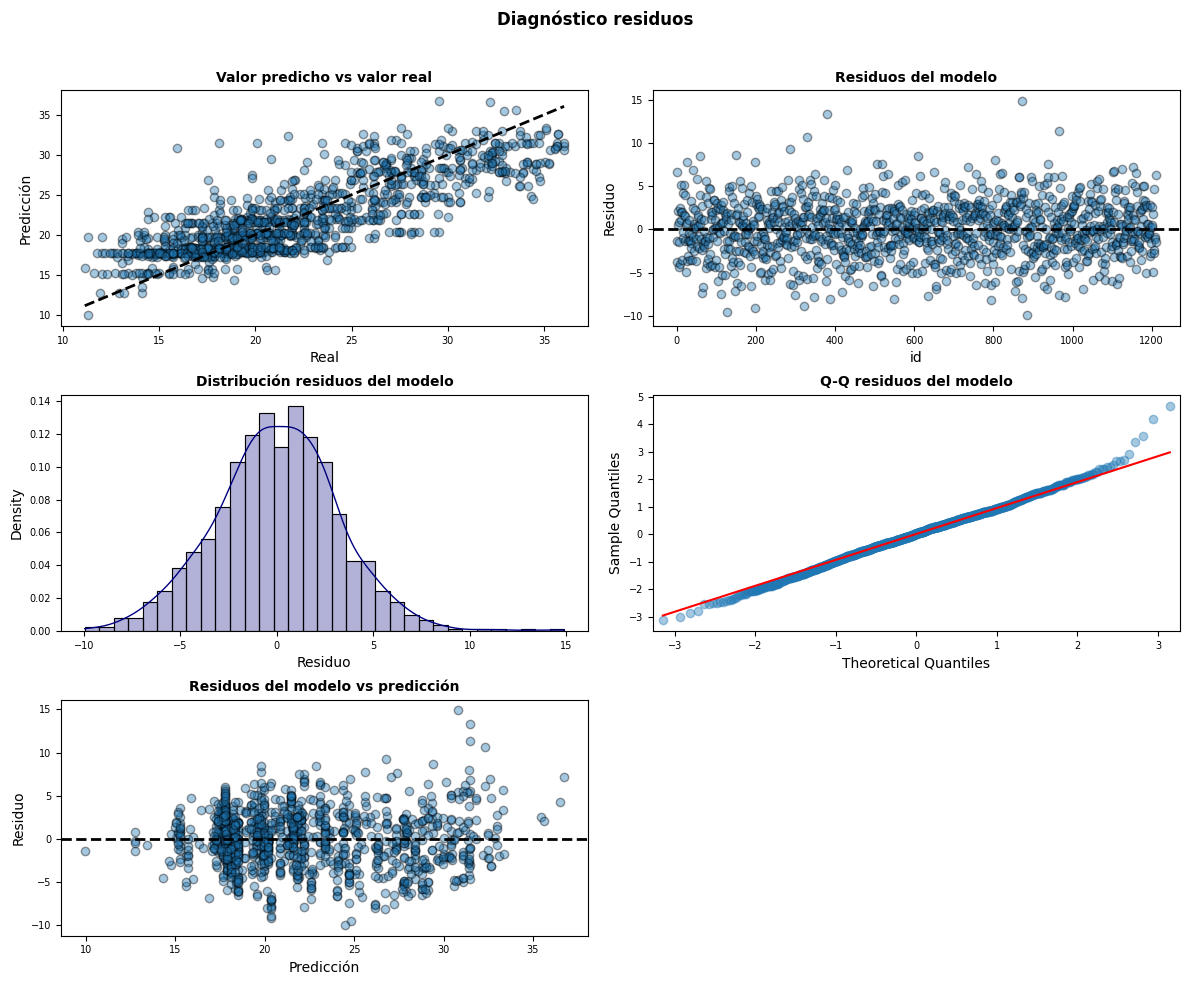

In [59]:
# Gráficos para el pronóstico de residuos

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10))

axes[0, 0].scatter(y_train, prediccion_train, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()],
                '--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    color   =  "navy",#"firebrick",
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10,
                     fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train,
    fit   = True,
    line  = 'q',
    ax    = axes[1, 1],
    color = 'navy', #'firebrick',
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train, residuos_train,
                   edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', color = 'black', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2,1])

fig.tight_layout()
plt.subplots_adjust(top=0.9)
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

### Test

In [60]:
#Se extraen solo las columnas que finalmente quedaron en X_train (excluyendo constante)
X_test = X_test[modelo_X_train.columns[1:len(modelo_X_train)]]

#Adicionamos la constante
X_test = sm.add_constant(X_test)

In [61]:
# Error de prueba (test) del modelo


predicciones = modelLRegresion.predict(X_test)

mse = mean_squared_error (y_true  = y_test, y_pred  = predicciones)
rmse = np.sqrt (mse)
MAE = mean_absolute_error (y_true  = y_test, y_pred  = predicciones)
MedAE = median_absolute_error (y_true  = y_test, y_pred  = predicciones)
r2 = r2_score (y_true  = y_test, y_pred  = predicciones)

print(f"El error MSE   de test es: {mse}")
print(f"El error RMSE  de test es: {rmse}")
print(f"El error MAE   de test es: {MAE}")
print(f"El error MedAE de test es: {MedAE}")
print(f"El error R2    de test es: {r2}")

El error MSE   de test es: 9.632834933311257
El error RMSE  de test es: 3.103680868470735
El error MAE   de test es: 2.4181694628357873
El error MedAE de test es: 1.9893722830771265
El error R2    de test es: 0.6630702988255803


In [62]:
X_test

,const,PriceRange,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_Fourth,Owner_Second,Owner_Third,Drivetrain_FWD,Drivetrain_RWD
366,1.0000,0.5000,0.6836,0,0,0,0,0,0,0,1
919,1.0000,0.7500,1.0000,0,0,0,0,0,0,0,0
34,1.0000,0.0000,0.0771,0,1,0,0,0,0,1,0
78,1.0000,0.0000,0.3461,0,0,1,0,0,0,1,0
1430,1.0000,0.5000,0.5902,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
27,1.0000,0.0000,0.3461,0,0,1,0,0,0,0,1
1368,1.0000,0.0000,0.1350,0,0,1,0,0,0,1,0
234,1.0000,0.0000,0.1350,0,0,1,0,1,0,1,0
362,1.0000,0.0000,0.1562,0,1,1,0,0,0,1,0


In [63]:
modelLRegresion.predict(X_test)

,0
366,31.4454
919,36.7396
34,21.5832
78,21.3576
1430,28.0800
...,...
27,21.4969
1368,19.7737
234,17.2487
362,18.4864


In [64]:
# Concatenar X_test y y_test
df_prep = pd.DataFrame(np.c_[X_test, y_test], columns= X_test.columns.tolist()+['PriceReal'])
df_prep

,const,PriceRange,Fuel Tank Capacity,Fuel Type_Otro,Fuel Type_Petrol,Transmission_Manual,Owner_Fourth,Owner_Second,Owner_Third,Drivetrain_FWD,Drivetrain_RWD,PriceReal
0,1.0000,0.5000,0.6836,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,32.2686
1,1.0000,0.7500,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,33.7373
2,1.0000,0.0000,0.0771,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,18.9824
3,1.0000,0.0000,0.3461,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,22.8177
4,1.0000,0.5000,0.5902,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,28.7243
...,...,...,...,...,...,...,...,...,...,...,...,...
299,1.0000,0.0000,0.3461,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,22.8943
300,1.0000,0.0000,0.1350,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,21.2443
301,1.0000,0.0000,0.1350,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,21.7295
302,1.0000,0.0000,0.1562,0.0000,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,21.0656


In [65]:
# Predecir los valores para df_prep utilizando el modelLRegresion y Elevar al cubo usando np.power()
resultadoPredict =np.power(modelLRegresion.predict(df_prep.drop(columns ='PriceReal')), 3)
resultadoPredict

,0
0,31093.5447
1,49590.9222
2,10054.2093
3,9742.2631
4,22140.7044
...,...
299,9934.1240
300,7731.5554
301,5131.7998
302,6317.7112


In [66]:
# Convertir el array numpy resultadoPredic en un DataFrame de pandas
resultadoPredict_df = pd.DataFrame(resultadoPredict, columns=['PricePredict'])
resultadoPredict_df

,PricePredict
0,31093.5447
1,49590.9222
2,10054.2093
3,9742.2631
4,22140.7044
...,...
299,9934.1240
300,7731.5554
301,5131.7998
302,6317.7112


In [67]:
# Concatenar x_i con el DataFrame de las predicciones
concatenated_df = pd.concat([df_prep.reset_index(drop=True), resultadoPredict_df], axis=1)

# el precio real se eleva al cubo
concatenated_df['PriceReal'] = np.power(concatenated_df['PriceReal'],3)

In [68]:
# Se calcula el valor absoluto de la diferencia entre el precio real y el precio calculado
concatenated_df['dif'] = (concatenated_df['PriceReal'] - concatenated_df['PricePredict']).abs()

In [69]:
# Las diferencias ordenadas
concatenated_df[['PriceReal', 'PricePredict', 'dif']].sort_values(by='dif', ascending=True)

,PriceReal,PricePredict,dif
247,14100.0000,14115.7974,15.7974
210,6132.0000,6155.8901,23.8901
66,6000.0000,5931.7051,68.2949
163,5100.0000,5190.4065,90.4065
193,3300.0000,3206.8810,93.1190
...,...,...,...
181,9900.0000,28666.7790,18766.7790
69,46200.0000,26976.0122,19223.9878
125,47400.0000,25284.8986,22115.1014
205,13800.0000,36953.0493,23153.0493


In [70]:
# Principales descripciones de las diferencias
print(concatenated_df['dif'].describe())

count     304.0000
mean     3766.5078
std      4180.1529
min        15.7974
25%      1059.0985
50%      2467.0101
75%      4977.8611
max     28257.5913
Name: dif, dtype: float64


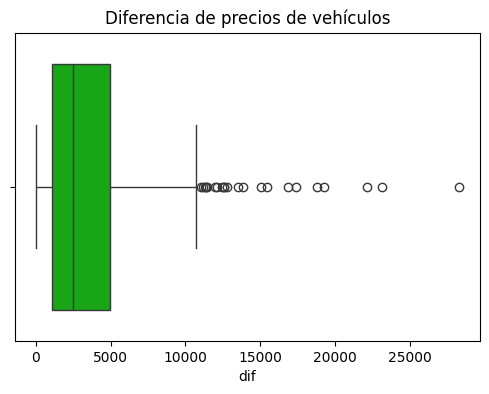

In [71]:
#Caja de bigotes de las diferencias de los precios

plt.figure(figsize=(6,4))

plt.title('Diferencia de precios de vehículos')
sns.boxplot(x=concatenated_df['dif'], palette='nipy_spectral')

plt.show()

#### Referencias

- *Regresion Lineal en Python:*
    - https://www.cienciadedatos.net/documentos/py10-regresion-lineal-python.html
  
  
- *Machine learning con Python y Scikit-learn:*
    - https://www.cienciadedatos.net/documentos/py06_machine_learning_python_scikitlearn.html
    

- *scikit-learn:*    
    - https://scikit-learn.org/stable/
    - https://scikit-learn.org/stable/user_guide.html
  
  
- *Recursive Feature Elimination (RFE)*:
    - https://www.kaggle.com/goyalshalini93/car-price-prediction-linear-regression-rfe
    - https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html


- *Gráficas con  seaborn:*
    - https://ichi.pro/es/como-utilizar-python-seaborn-para-analisis-de-datos-exploratorios-28897898172180


- *Multicolinealidad:*
    - https://www.analyticslane.com/2020/04/22/solucionar-la-multicolinealidad-con-vif/


- *Analítica de grandes datos:*
    - https://jdvelasq.github.io/courses/analitica-de-grandes-datos/index.html